# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module — Research Assignment**

**Author:** Shubhra Narain  |  **Roll No.:** IMS25197

This notebook implements **recursive spectral modularity partitioning** from scratch (NumPy + NetworkX only for graph handling/metrics) on Zachary's Karate Club network, following Newman (2006).

**Plan**
1. Build the modularity matrix $B = A - \frac{kk^\top}{2m}$ and verify its properties (symmetry, $B\mathbf 1 = 0$).
2. Implement spectral bisection with the leading eigenvector, and recursive bisection with the stopping rule $\lambda_1^{(C)} \le 0$.
3. Visualise the partition after every iteration (fixed layout).
4. Compute degree / betweenness / closeness centrality and clustering after every iteration.
5. Plot their evolution and discuss.

**Reference:** M. E. J. Newman, *Modularity and community structure in networks*, PNAS **103**(23), 8577–8582 (2006).

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 110

## 1. Data: Zachary's Karate Club
34 nodes, 78 edges. NetworkX stores the *actual* post-split faction of each member in the node attribute `club` (`'Mr. Hi'` or `'Officer'`) — this is our ground truth, **never used by the algorithm**, only for evaluation afterwards.

In [ ]:
G = nx.karate_club_graph()
# Recent NetworkX versions attach edge weights to this graph; the assignment uses the plain
# unweighted graph (A_ij in {0,1}), so strip them to avoid accidentally using them anywhere.
for u, v in G.edges():
    G[u][v].pop("weight", None)
nodes = list(G.nodes())              # 0..33, so index i in matrices == node i
n, m = G.number_of_nodes(), G.number_of_edges()
print(f"n = {n}, m = {m}")

# Ground truth (for evaluation only)
truth = {v: G.nodes[v]["club"] for v in G}
truth_groups = {c: sorted(v for v in G if truth[v] == c) for c in set(truth.values())}

# One fixed layout, reused for every figure so that changes are visible
pos = nx.spring_layout(G, seed=42)

n = 34, m = 78


## 2. The modularity matrix
$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}, \qquad Q = \frac{1}{4m}\, s^\top B s .$$
We check Proposition 1 ($B$ real symmetric) and Proposition 2 ($B\mathbf 1 = 0$) numerically.

In [ ]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted 0/1 adjacency matrix (n x n)
k = A.sum(axis=1)                              # degree vector
B = A - np.outer(k, k) / (2 * m)               # modularity matrix

print("B symmetric          :", np.allclose(B, B.T))
print("B @ 1 == 0           :", np.allclose(B @ np.ones(n), 0))
print("sum of degrees == 2m :", k.sum() == 2 * m)
print("Q(trivial partition) :", np.ones(n) @ B @ np.ones(n) / (4 * m))

B symmetric          : True
B @ 1 == 0           : True
sum of degrees == 2m : True
Q(trivial partition) : 8.718097469011646e-18


## 3. Spectral bisection and recursive bisection

**Leading eigenpair.** `B` restricted to a group is real symmetric, so `np.linalg.eigh` (which returns eigenvalues in ascending order and orthonormal eigenvectors) is the right tool.

**Restricted matrix.** As specified in the handout, for a group $C$ we take the block $B^{(C)}_{ij} = B_{ij}$, $i,j\in C$.

> **A caveat worth knowing (relevant for the conceptual question).** For the *whole* graph the row sums of $B$ vanish, so splitting $V$ changes $Q$ by exactly $\frac{1}{4m}s^\top B s$. For a *proper subgroup* $C$ the row sums of the block $B^{(C)}$ do **not** vanish, and the exact modularity change from splitting $C$ is
> $$\Delta Q=\frac{1}{4m}\, s^\top B^{(g)} s,\qquad B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$$
> (Newman 2006, Eq. 6). The handout's version (plain block) is a good approximation and is what the task asks for; I implement **both** through a flag and compare them in Section 8. The default follows the handout.

In [ ]:
def leading_eigenpair(M):
    # Largest eigenvalue and (unit-norm) eigenvector of a real symmetric matrix.
    vals, vecs = np.linalg.eigh(M)       # ascending order
    return vals[-1], vecs[:, -1]


def restricted_B(B, idx, newman_correction=False):
    # Block of B on index set idx. Optionally subtract the diagonal row sums (Newman, Eq. 6).
    idx = np.asarray(idx)
    Bc = B[np.ix_(idx, idx)].copy()
    if newman_correction:
        Bc -= np.diag(Bc.sum(axis=1))
    return Bc


def bisect(B, idx, newman_correction=False, check_dQ=False, tol=1e-10):
    # Try to split the group idx. Returns (lambda1, C_plus, C_minus) or (lambda1, None, None) if indivisible.
    idx = np.asarray(idx)
    if len(idx) < 2:
        return 0.0, None, None
    lam, u = leading_eigenpair(restricted_B(B, idx, newman_correction))
    if lam <= tol:                              # stopping rule: lambda_1 <= 0
        return lam, None, None
    s = np.where(u > 0, 1, -1)                  # threshold: +1 if u_i > 0 else -1
    plus, minus = idx[s == 1], idx[s == -1]
    if len(plus) == 0 or len(minus) == 0:       # degenerate split: nothing actually separated
        return lam, None, None
    if check_dQ:                                # Newman's extra safeguard: rounding can lose the gain
        Bg = restricted_B(B, idx, newman_correction=True)
        sv = np.where(np.isin(idx, plus), 1, -1)
        if sv @ Bg @ sv <= tol:
            return lam, None, None
    return lam, plus, minus


def modularity(A, groups):
    # Q = (1/2m) sum_ij (A_ij - k_i k_j / 2m) * delta(c_i, c_j) for a list of index arrays.
    kk = A.sum(axis=1); two_m = kk.sum()
    Q = 0.0
    for g in groups:
        g = np.asarray(g)
        Q += A[np.ix_(g, g)].sum() - kk[g].sum() ** 2 / two_m
    return Q / two_m

In [ ]:
def recursive_bisection(A, B, newman_correction=False, check_dQ=False):
    # Level-by-level recursive bisection. history[t] = list of communities after iteration t.
    # history[0] is the trivial single community.
    groups = [np.arange(A.shape[0])]
    history = [[g.copy() for g in groups]]
    log = []                                      # (iteration, group size, lambda1, split?)
    t = 0
    while True:
        t += 1
        new_groups, any_split = [], False
        for g in groups:
            lam, plus, minus = bisect(B, g, newman_correction, check_dQ)
            if plus is None:
                new_groups.append(g)              # indivisible -> keep as is
                log.append((t, len(g), lam, False))
            else:
                new_groups += [plus, minus]
                any_split = True
                log.append((t, len(g), lam, True))
        if not any_split:                         # every group is stable: stop
            break
        groups = new_groups
        history.append([g.copy() for g in groups])
    return history, log


history, log = recursive_bisection(A, B)

print(pd.DataFrame(log, columns=["iteration", "|C|", "lambda_1", "split"]).to_string(index=False))
print()
for t, groups in enumerate(history):
    print(f"iteration {t}: {len(groups)} communities, Q = {modularity(A, groups):.4f}")

 iteration  |C|  lambda_1  split
         1   34  4.977080   True
         2   16  2.944129   True
         2   18  2.504088   True
         3   10  2.571158  False
         3    6  2.147993   True
         3    5  1.875925  False
         3   13  2.356350  False
         4   10  2.571158  False
         4    1  0.000000  False
         4    5  2.147005  False
         4    5  1.875925  False
         4   13  2.356350  False

iteration 0: 1 communities, Q = 0.0000
iteration 1: 2 communities, Q = 0.3715
iteration 2: 4 communities, Q = 0.4081
iteration 3: 5 communities, Q = 0.4094


Iteration 0 is the whole graph (one community, $Q=0$); each later iteration is one *round* of splitting applied to every currently-splittable community. The final row of the log lists the round in which no group was splittable.

## 4. Visualisation after every split
Fixed layout, one colour per community, node IDs as labels.

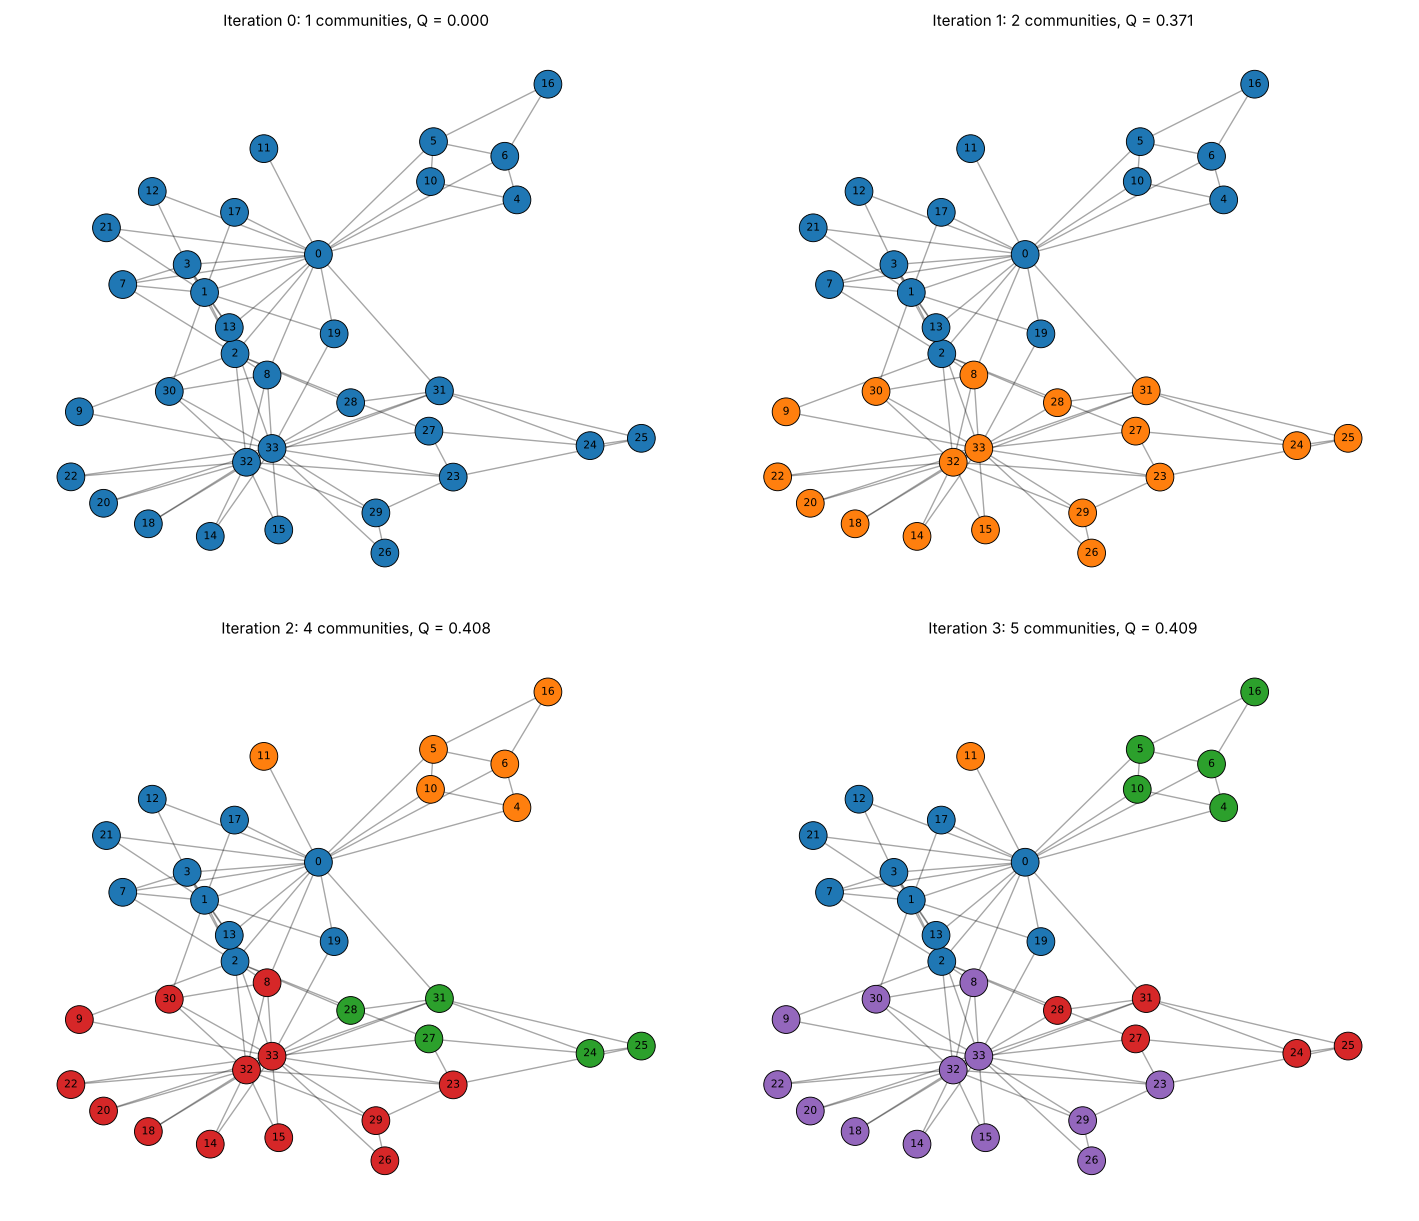

In [ ]:
palette = plt.cm.tab10.colors

def draw_partition(ax, groups, title):
    colour = {}
    for ci, g in enumerate(groups):
        for v in g:
            colour[int(v)] = palette[ci % len(palette)]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[colour[v] for v in G], node_size=330,
                           edgecolors="k", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10); ax.axis("off")

T = len(history)
ncols = 2
nrows = int(np.ceil(T / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 5.6 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax in axes[T:]:
    ax.axis("off")
for t, (ax, groups) in enumerate(zip(axes, history)):
    draw_partition(ax, groups, f"Iteration {t}: {len(groups)} communities, Q = {modularity(A, groups):.3f}")
plt.tight_layout(); plt.show()

### Comparison with the real split
The first split (iteration 1) is the one that corresponds to the historical fission of the club.

Mr. Hi faction (truth)   : [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 16, 17, 19, 21]
Predicted community      : [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Misclassified nodes      : [8]  (33/34 correct)


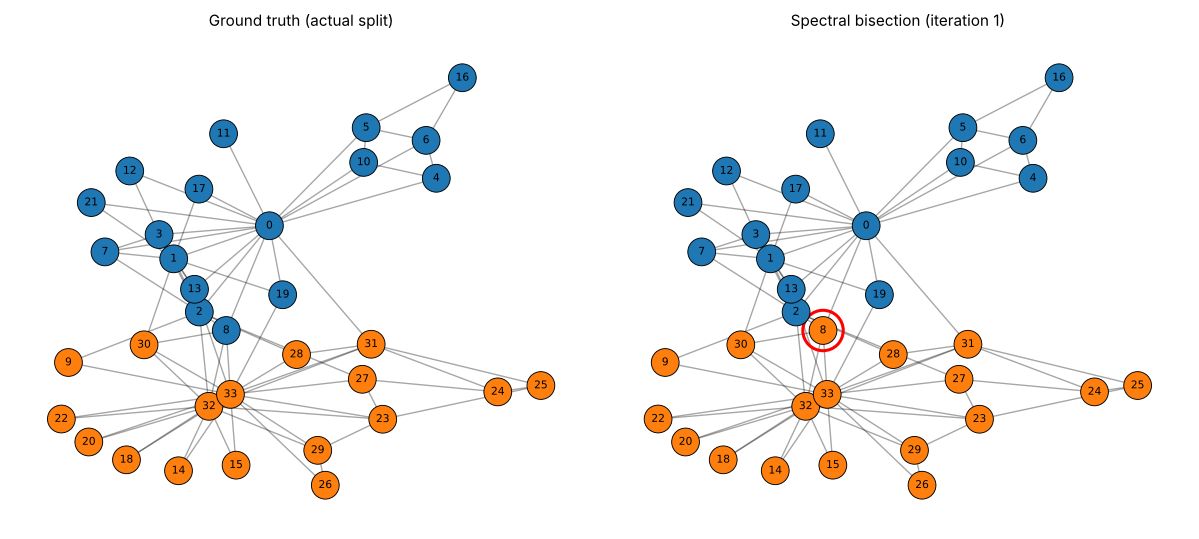

In [ ]:
first = history[1] if len(history) > 1 else history[0]
pred = {int(v): ci for ci, g in enumerate(first) for v in g}
hi_group = truth_groups["Mr. Hi"]

# Which predicted community overlaps most with Mr. Hi's faction?
best = max(range(len(first)), key=lambda ci: len(set(map(int, first[ci])) & set(hi_group)))
pred_hi = set(map(int, first[best]))
true_hi = set(hi_group)
mis = sorted((pred_hi ^ true_hi))
print("Mr. Hi faction (truth)   :", sorted(true_hi))
print("Predicted community      :", sorted(pred_hi))
print(f"Misclassified nodes      : {mis}  ({n - len(mis)}/{n} correct)")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
draw_partition(axes[0], [np.array(sorted(true_hi)), np.array(sorted(set(range(n)) - true_hi))], "Ground truth (actual split)")
draw_partition(axes[1], first, "Spectral bisection (iteration 1)")
for v in mis:
    axes[1].scatter(*pos[v], s=700, facecolors="none", edgecolors="red", linewidths=2)
plt.tight_layout(); plt.show()

## 5. Node metrics after every iteration
Computed with NetworkX built-ins:
`degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`.

**Design choice.** If the metrics were computed on the *full* graph $G$ they would never change with the iteration. To make "evolution across iterations" meaningful, after each split I compute them on the graph $G_t$ that keeps **only intra-community edges** (all nodes retained, edges between different communities removed). Iteration 0 therefore equals the original graph $G$. Because $G_t$ is disconnected after the first split, NetworkX closeness uses its default Wasserman–Faust correction for disconnected graphs.

In [ ]:
def community_graph(groups):
    # Graph on all nodes keeping only edges inside a community.
    lab = {int(v): ci for ci, g in enumerate(groups) for v in g}
    H = nx.Graph(); H.add_nodes_from(G.nodes())
    H.add_edges_from((u, v) for u, v in G.edges() if lab[u] == lab[v])
    return H

metric_funcs = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

# metrics[name][iteration] = {node: value}   (dictionary keyed by iteration number, as requested)
metrics = {name: {} for name in metric_funcs}
for t, groups in enumerate(history):
    H = community_graph(groups)
    for name, f in metric_funcs.items():
        metrics[name][t] = f(H)

# sanity check: iteration 0 must reproduce the original graph's metrics
assert all(abs(metrics["Betweenness centrality"][0][v] - nx.betweenness_centrality(G)[v]) < 1e-12 for v in G)

tables = {name: pd.DataFrame(metrics[name]).sort_index().rename(columns=lambda t: f"iter {t}")
          for name in metrics}
tables["Degree centrality"].round(3).head(10)

,iter 0,iter 1,iter 2,iter 3
0,0.485,0.424,0.273,0.273
1,0.273,0.242,0.242,0.242
2,0.303,0.152,0.152,0.152
3,0.182,0.182,0.182,0.182
4,0.091,0.091,0.061,0.061
5,0.121,0.121,0.091,0.091
6,0.121,0.121,0.091,0.091
7,0.121,0.121,0.121,0.121
8,0.152,0.091,0.091,0.091
9,0.061,0.030,0.030,0.030


## 6. Evolution of the metrics
For each metric: (left) a heatmap over all 34 nodes × iterations; (right) the trajectories of the five nodes with the highest iteration-0 value, with everything else in grey for context.

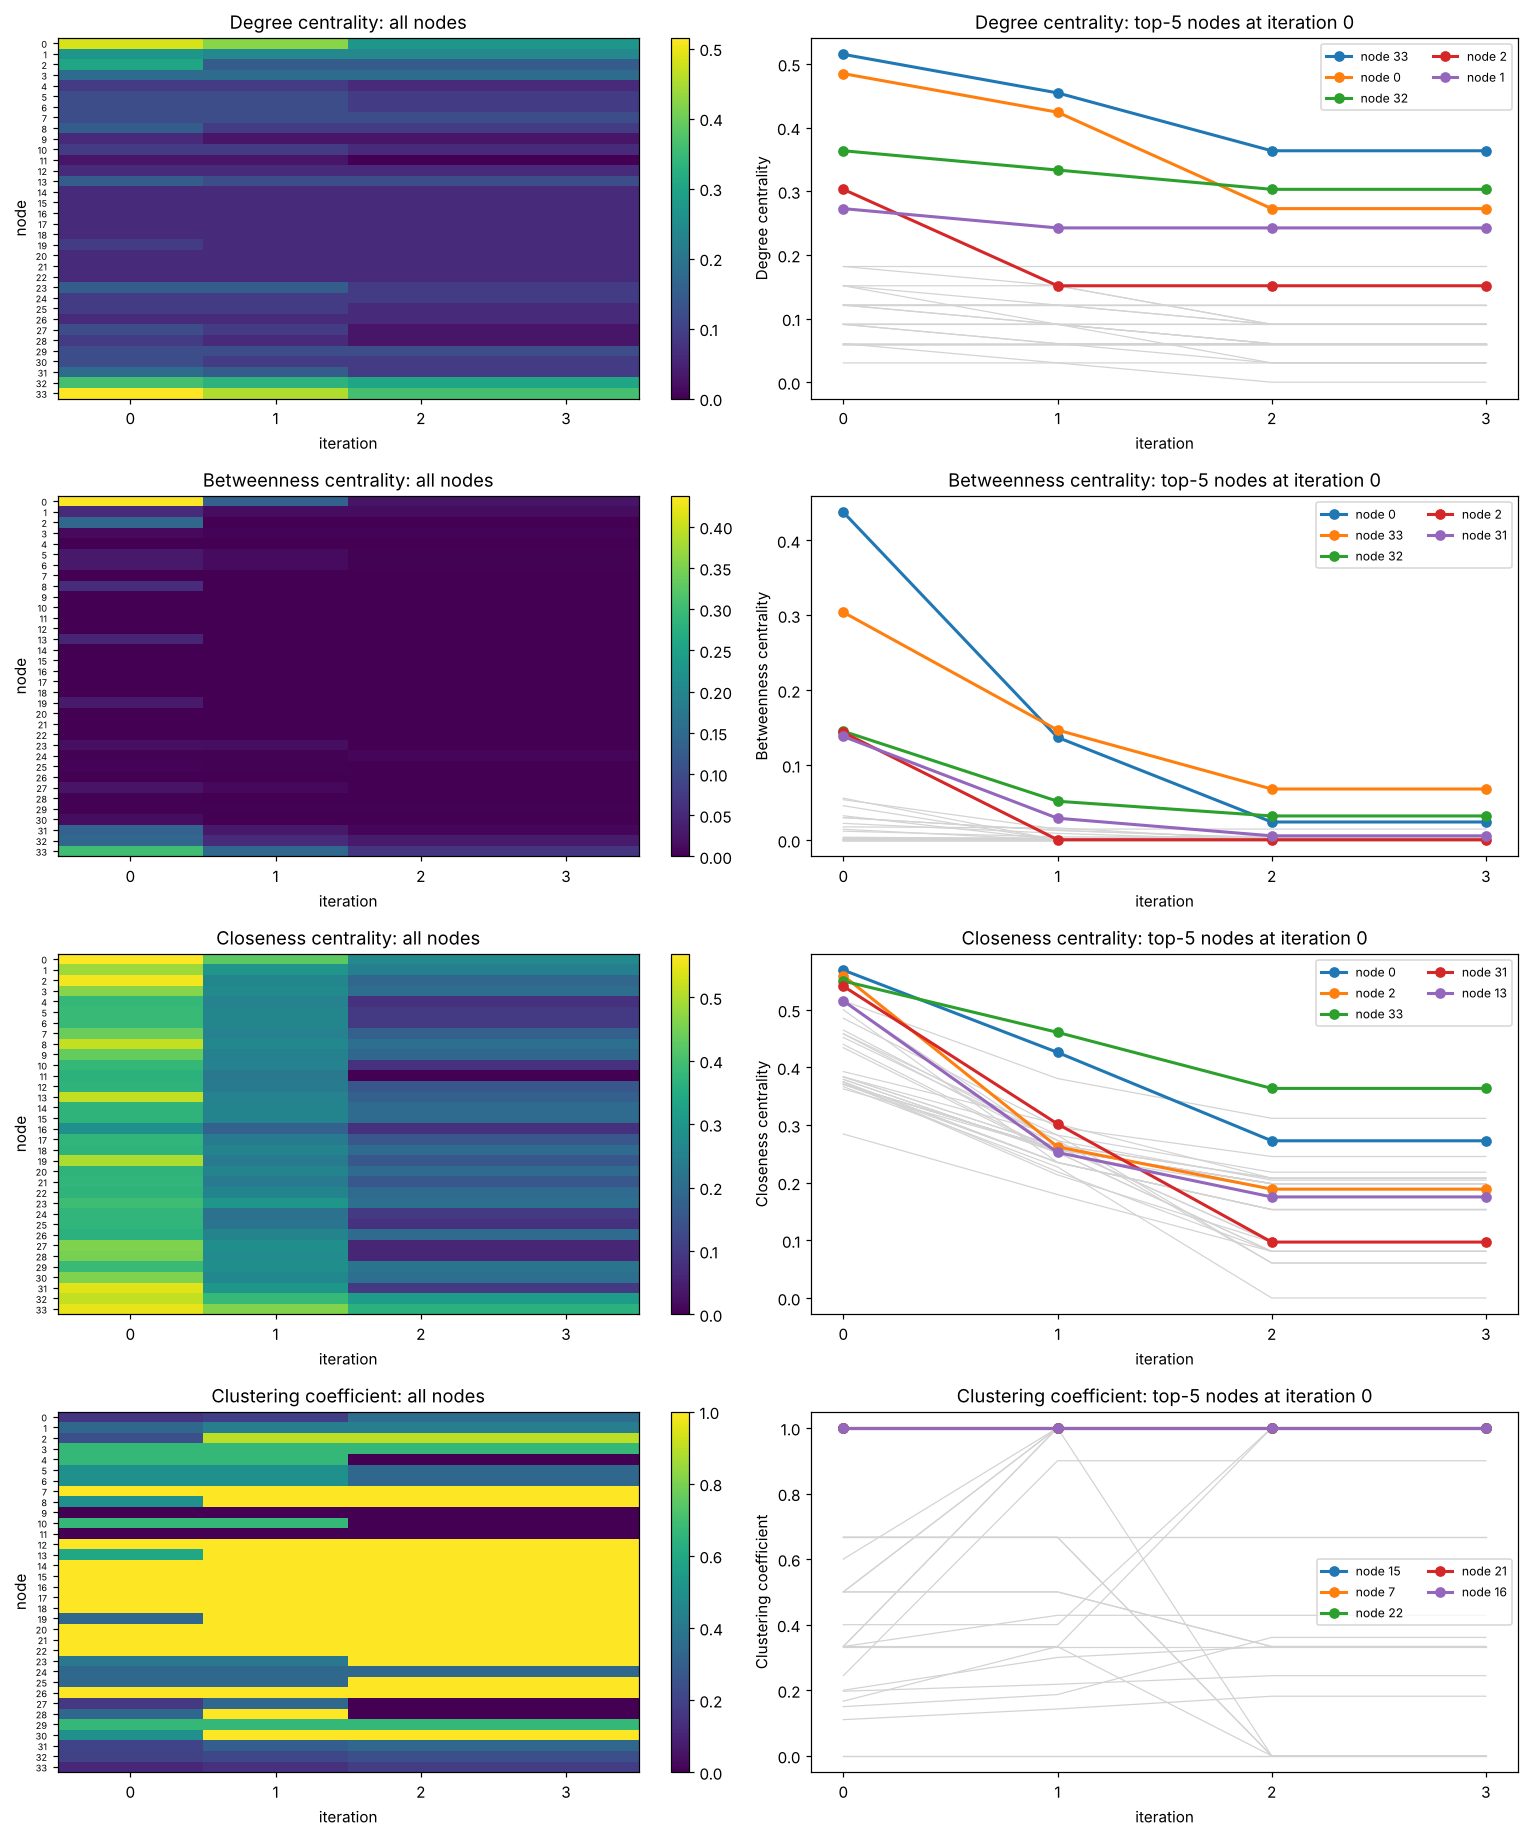

In [ ]:
iters = list(range(len(history)))
fig, axes = plt.subplots(len(metrics), 2, figsize=(14, 4.2 * len(metrics)),
                         gridspec_kw={"width_ratios": [1, 1.1]})

for r, (name, df) in enumerate(tables.items()):
    ax = axes[r, 0]
    im = ax.imshow(df.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(iters))); ax.set_xticklabels(iters)
    ax.set_yticks(range(n)); ax.set_yticklabels(df.index, fontsize=6)
    ax.set_xlabel("iteration"); ax.set_ylabel("node")
    ax.set_title(f"{name}: all nodes")
    plt.colorbar(im, ax=ax, fraction=0.046)

    ax = axes[r, 1]
    for v in df.index:
        ax.plot(iters, df.loc[v].values, color="lightgrey", lw=0.8, zorder=1)
    top = df["iter 0"].sort_values(ascending=False).head(5).index
    for v in top:
        ax.plot(iters, df.loc[v].values, marker="o", lw=2, label=f"node {v}", zorder=3)
    ax.set_xticks(iters); ax.set_xlabel("iteration"); ax.set_ylabel(name)
    ax.set_title(f"{name}: top-5 nodes at iteration 0")
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

Per-node trajectories for **all** 34 nodes, one small panel per metric, are also provided (consistent colours by final community) so any single node can be traced.

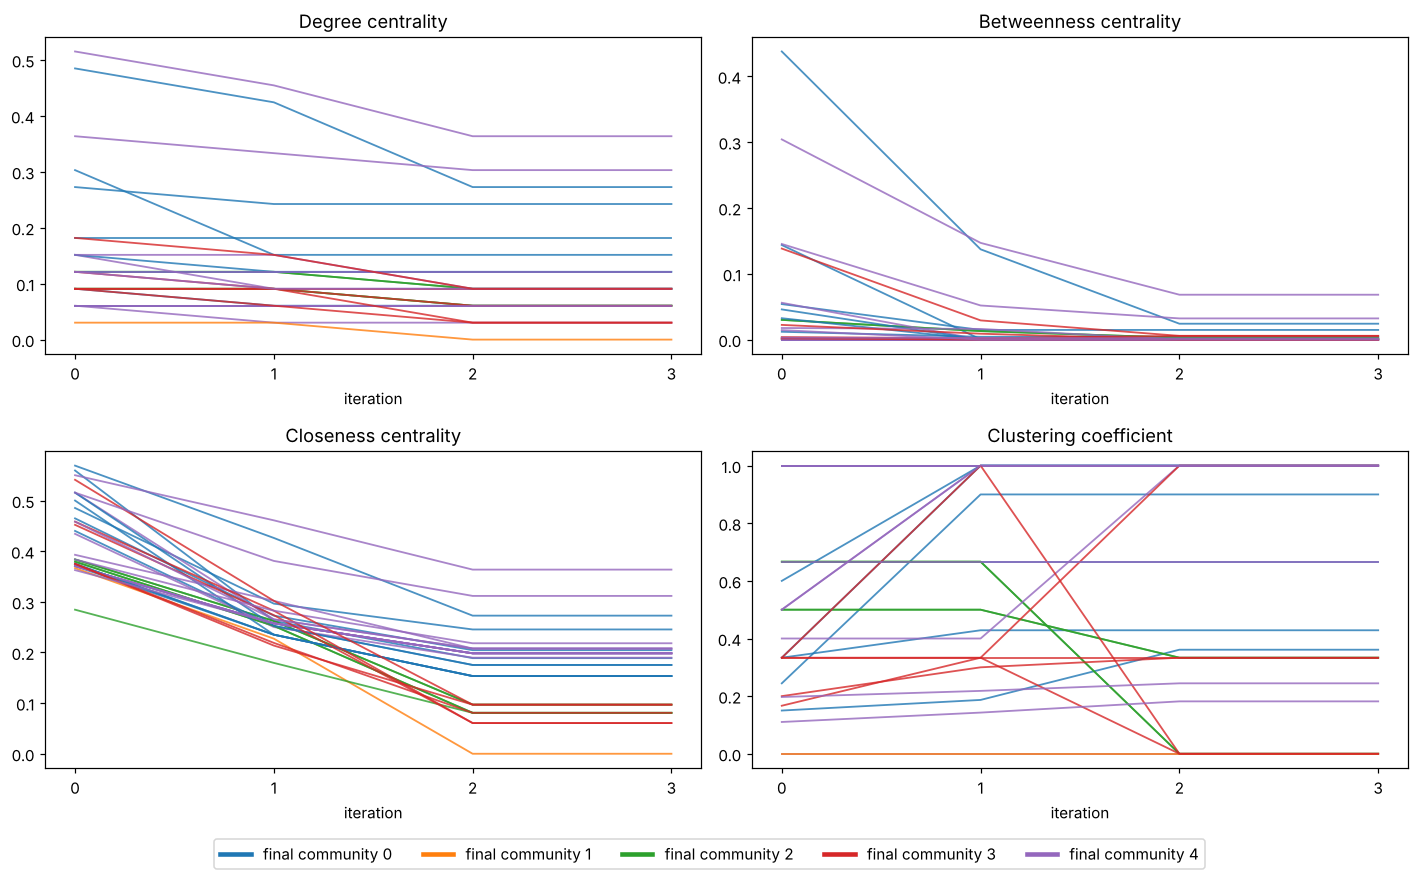

In [ ]:
final = history[-1]
final_label = {int(v): ci for ci, g in enumerate(final) for v in g}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (name, df) in zip(axes.ravel(), tables.items()):
    for v in df.index:
        ax.plot(iters, df.loc[v].values, color=palette[final_label[v] % 10], alpha=0.8, lw=1.2)
    ax.set_xticks(iters); ax.set_title(name); ax.set_xlabel("iteration")
handles = [plt.Line2D([0], [0], color=palette[ci % 10], lw=3, label=f"final community {ci}") for ci in range(len(final))]
fig.legend(handles=handles, loc="lower center", ncol=len(final))
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

## 7. Which nodes stay central?
Rank nodes by each metric at every iteration and look at who stays in the top 5.

In [ ]:
top_k = 5
summary = {}
for name, df in tables.items():
    in_top = pd.DataFrame({c: df[c].rank(ascending=False, method="min") <= top_k for c in df.columns})
    summary[name] = in_top.sum(axis=1)               # number of iterations in the top-5

summary = pd.DataFrame(summary)
summary["total"] = summary.sum(axis=1)
print(f"Number of iterations (out of {len(iters)}) in which a node is in the top {top_k}:")
summary.sort_values("total", ascending=False).head(8)

Number of iterations (out of 4) in which a node is in the top 5:


,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient,total
0,4,4,4,0,12
32,4,4,4,0,12
33,4,4,4,0,12
1,4,2,2,0,8
31,0,4,2,0,6
8,0,0,1,3,4
14,0,0,0,4,4
7,0,0,0,4,4


## 8. Extra check: handout recursion vs. exact (Newman-corrected) recursion
The handout restricts $B$ to a block; Newman's exact generalised matrix also subtracts the diagonal row sums. Both are run and compared against `networkx`'s independent modularity function.

In [ ]:
from networkx.algorithms.community import modularity as nx_modularity

def as_sets(groups): return [set(map(int, g)) for g in groups]

for label, flag in [("Handout (plain block)", False), ("Newman-corrected + dQ check", True)]:
    h, _ = recursive_bisection(A, B, newman_correction=flag, check_dQ=flag)
    final_groups = h[-1]
    q_mine = modularity(A, final_groups)
    q_nx = nx_modularity(G, as_sets(final_groups), weight=None)
    print(f"{label:28s}: {len(final_groups)} communities | Q (mine) = {q_mine:.4f} | Q (networkx) = {q_nx:.4f}")
    for g in final_groups:
        print("    ", sorted(map(int, g)))

# Reference points
print("\nNetworkX greedy modularity (CNM) for comparison:",
      round(nx_modularity(G, nx.algorithms.community.greedy_modularity_communities(G, weight=None), weight=None), 4))
print("Q of the true two-faction split                  :",
      round(nx_modularity(G, [set(hi_group), set(range(n)) - set(hi_group)], weight=None), 4))

Handout (plain block)       : 5 communities | Q (mine) = 0.4094 | Q (networkx) = 0.4094
     [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
     [11]
     [4, 5, 6, 10, 16]
     [24, 25, 27, 28, 31]
     [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Newman-corrected + dQ check : 4 communities | Q (mine) = 0.3934 | Q (networkx) = 0.3934
     [0, 4, 5, 6, 10, 11, 16]
     [1, 2, 3, 7, 12, 13, 17, 19, 21]
     [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
     [23, 24, 25, 27, 28, 31]

NetworkX greedy modularity (CNM) for comparison: 0.3807
Q of the true two-faction split                  : 0.3582


## 9. Discussion

### 9.1 What the algorithm found
| Iteration | # communities | $Q$ |
|---|---|---|
| 0 (whole graph) | 1 | 0.000 |
| 1 | 2 | 0.372 |
| 2 | 4 | 0.408 |
| 3 | 5 | 0.409 |

* **The first split recovers the real fission of the club.** 33 of 34 members land on the correct side; the only error is **node 8**, who has strong ties to both leaders (and, historically, is known to be a hard case for essentially every method). $Q=0.372$ for this bisection is also *higher* than the $Q = 0.358$ of the true two-faction split, i.e. the algorithm finds a split that is *better by the modularity criterion* than the one that actually happened.
* **Further rounds refine the factions into sub-communities.** Mr. Hi's side splits into a core around nodes 0–1–2–3 and a peripheral cluster {4, 5, 6, 10, 16}; the officer's side splits into a large group around 32/33 and a smaller group {24, 25, 27, 28, 31}. Node 11 (degree 1, attached to node 0) is finally detached as a singleton, a feature of the handout's plain-block criterion discussed below. The gain in $Q$ shrinks quickly (0.372 → 0.408 → 0.409), so past iteration 2 the extra communities are statistically marginal.

### 9.2 A note on the stopping rule (important for understanding)
The handout states that recursion stops when $\lambda_1^{(C)}\le 0$. Numerically (see the log in Section 3) the plain block $B^{(C)}$ almost always keeps $\lambda_1>0$, because its row sums are *not* zero (only the full matrix satisfies $B\mathbf 1=0$). The recursion then really terminates because the sign vector of the leading eigenvector becomes **all one sign**, i.e. there is nothing to separate. The exact generalised matrix of Newman (2006, Eq. 6), $B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$, restores the zero-row-sum property so that $\lambda_1^{(C)}\ge 0$ with $\lambda_1=0$ exactly for an indivisible group, and gives the true $\Delta Q=\frac1{4m}s^\top B^{(g)}s$. Section 8 shows that this variant yields 4 communities with $Q=0.393$ versus 5 communities with $Q=0.409$ for the handout variant, so the two differ in detail while agreeing on the main structure. One further subtlety: $\lambda_1>0$ guarantees only that the *relaxed* (real-valued) problem can gain; after rounding to $\pm1$ the gain is not guaranteed, which is why Newman also checks $\Delta Q>0$ explicitly (done in the corrected variant).

### 9.3 Which nodes remain central?
* **Nodes 0, 32 and 33 are in the top 5 for degree, betweenness and closeness at every iteration** (Section 7). Node 33 (the club administrator/officer side) has the highest degree centrality in $G$ (0.515) and keeps the highest degree and closeness after every split; node 0 (the instructor, "Mr. Hi") has the highest betweenness in the full graph (0.438). Node 1 stays in the top 5 for degree throughout, and node 31 for betweenness: hubs *inside* a community stay hubs inside it.
* The two leaders are the hubs of the two factions, so they are central whether the graph is considered as a whole or only within each community: their centrality is "local", driven by their many links inside their own group.

### 9.4 How community structure changes the metrics
(All metrics are computed on $G_t$, the graph restricted to intra-community edges, so part of every change is the *mechanical* effect of deleting cross-community edges. What is informative is *which nodes change most*.)
* **Degree centrality** can only decrease. It drops most for nodes with many cross-community links: node 0 falls from 0.485 to 0.273 and node 2 from 0.303 to 0.152.
* **Betweenness collapses after the first split**, e.g. node 0: 0.438 → 0.137 → 0.024; node 2: 0.144 → 0; node 8: 0.056 → 0. In the full graph a large part of betweenness comes from shortest paths that *cross* between the two factions; once those inter-community edges are removed, nodes that were **bridges/brokers** (2, 8, 31, 0) lose their brokerage role while nodes embedded in a community keep theirs.
* **Closeness** decreases because distances are now measured only within the (smaller, partially disconnected) communities and NetworkX penalises unreachable nodes. By the last iteration the lowest values belong to node 11 (an isolated singleton, closeness 0) and to nodes 27 and 28 in the small peripheral community {24, 25, 27, 28, 31}.
* **Clustering increases for boundary nodes.** Edges between communities typically close few triangles, so deleting them leaves neighbourhoods that are cliquish: node 2 goes 0.244 → 0.900, node 8 goes 0.5 → 1.0, node 0 goes 0.150 → 0.361, node 31 goes 0.200 → 0.333. Clustering is highest for low-degree nodes in dense cores (e.g. node 16) and is *anti*-correlated with the hub/broker role: the three most central nodes (0, 32, 33) are never in the top 5 for clustering.

**Take-home message.** Modularity-based communities separate two kinds of central node: *hubs* (high degree within a group; 0, 33, 32) whose centrality survives the partition, and *brokers* (high betweenness because they sit between groups; 2, 8, 31, and partly 0) whose centrality is largely a property of the *between-community* edges and so vanishes when those are removed.

## 10. Reproducibility notes
* Layout seed fixed (`spring_layout(seed=42)`); the algorithm itself is deterministic.
* Requires: `numpy`, `networkx`, `matplotlib`, `pandas`.
* Ground-truth labels are used **only** for the comparison in Section 4, never by the algorithm.